# Experiment comparison
Compare saved experiment metrics without training or inference.

First, all the models will be shown, then it is possible to select runs in `RUNS`. The best model in the tables will be selected according to the validation metrics. Test set has been used only as a further evidence.

In [1]:
from pathlib import Path
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
MODELS_DIR = PROJECT_ROOT / "output" / "models"
pd.set_option("display.max_columns", 30)

## 1. Available checkpoints
The inventory reads filenames and sizes only. Prefer `last.pth`: it usually contains the full history and may include the final test evaluation of the best model. `best.pth` can contain a shorter history and no test metrics.

In [2]:
inventory = pd.DataFrame([
    {"checkpoint": str(p.relative_to(MODELS_DIR)), "size (MB)": round(p.stat().st_size / 2**20, 1)}
    for p in sorted(MODELS_DIR.rglob("*.pth"))
])
display(inventory)

,checkpoint,size (MB)
0,backups\backup_v0_20epochs_2026-10-16.pth,90.1
1,backups\backup_v2_S1_20epochs_2026-10-14.pth,90.0
2,backups\backup_v2_S2_20epochs_2026-10-14.pth,90.0
3,backups\backup_v2_S3_20epochs_2026-10-08.pth,90.1
4,backups\backup_v3_20epochs_2026-10-12.pth,90.0
5,CustomResNet18\v0_RGB_LRO_20261110\best_acc.pth,129.6
6,CustomResNet18\v0_RGB_LRO_20261110\best_loss.pth,86.9
7,CustomResNet18\v0_RGB_LRO_20261110\last.pth,129.6
8,CustomResNet18\v4_Kmin1024_LRO_20261106\best_a...,129.5
9,CustomResNet18\v4_Kmin1024_LRO_20261106\best_l...,86.8


## 2. Select experiments
Paths below are relative to `MODELS_DIR` (absolute paths also work). Keep `RUNS` empty to select one `last.pth` per run automatically, excluding backup folders. Use explicit entries to compare a smaller group.

`METADATA` supplies optional, manually verified descriptions for older checkpoints. Never infer Kmin, color space, architecture or freezing policy from a folder name. Manual metadata is displayed separately and does not override saved metrics.

In [3]:
RUNS = {
    # "v4 baseline": "valid_v4_cumulative_rank_adaptive_MSB_20261022/last.pth",
    # "v4 scheduler": "valid_v4_Kmin128_LRO_20261103/last.pth",
    "v0 baseline_RN50": "valid_v0_20261023/last.pth",
    "v4 baseline_RN50": "valid_v4_cumulative_rank_adaptive_MSB_20261022/last.pth",
    "v4_Kmin1024_RN50": "valid_v4_Kmin1024_LRO_20261105/last.pth",
    "v4_Kmin128_RN50":  "valid_v4_Kmin128_LRO_20261102/last.pth",
    "vo_baseline_RN18": "CustomResNet18/v0_RGB_LRO_20261110/last.pth",
    "v4_Kmin1024_RN18": "CustomResNet18/v4_Kmin1024_LRO_20261106/last.pth",
    "v4_Kmin128_RN18":  "CustomResNet18/v4_Kmin128_LRO_20261106/last.pth"
    
}
METADATA = {
    # "v4 baseline": {"architecture": "ResNet50", "Kmin": None, "color_space": "RGB"},
}

if not RUNS:
    RUNS = {
        str(p.parent.relative_to(MODELS_DIR)): p
        for p in sorted(MODELS_DIR.rglob("last.pth"))
        if not any("backup" in part.lower() for part in p.relative_to(MODELS_DIR).parts)
    }
print(f"Selected {len(RUNS)} checkpoints.")

Selected 7 checkpoints.


In [4]:
# run this cell to see all the models selected for evaluation. You can also modify the RUNS dictionary above to select specific checkpoints.
RUNS

{'v0 baseline_RN50': 'valid_v0_20261023/last.pth',
 'v4 baseline_RN50': 'valid_v4_cumulative_rank_adaptive_MSB_20261022/last.pth',
 'v4_Kmin1024_RN50': 'valid_v4_Kmin1024_LRO_20261105/last.pth',
 'v4_Kmin128_RN50': 'valid_v4_Kmin128_LRO_20261102/last.pth',
 'vo_baseline_RN18': 'CustomResNet18/v0_RGB_LRO_20261110/last.pth',
 'v4_Kmin1024_RN18': 'CustomResNet18/v4_Kmin1024_LRO_20261106/last.pth',
 'v4_Kmin128_RN18': 'CustomResNet18/v4_Kmin128_LRO_20261106/last.pth'}

## 3. Read saved results and check comparability
Validation metrics use `best_acc_epoch` when saved; older checkpoints fall back to the minimum-validation-loss epoch. `best_epoch` and `selection` identify the selected epoch and criterion, while `best_loss_epoch` and `best_acc_epoch` retain the saved references. Test metrics carry their own epoch and are not recomputed. A saved split fingerprint checks the partition and label mapping, not the contents of the original image files. Verify that test datasets also contain the same examples; older checkpoints may not record their identity.

Accuracy uses percent (0–100). Per-class metrics below are converted to percent too. Training time excludes validation, saving and setup; different hardware or timing coverage makes time comparisons approximate.

In [5]:
def extract_run(label, path):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    history = pd.DataFrame(checkpoint.get("history", []))
    best_loss_epoch = checkpoint.get("best_loss_epoch", checkpoint.get("best_epoch"))
    best_acc_epoch = checkpoint.get("best_acc_epoch")
    use_best_acc = best_acc_epoch is not None
    best_epoch = best_acc_epoch if use_best_acc else best_loss_epoch
    best_rows = history.loc[history["epoch"].eq(best_epoch)] if "epoch" in history else pd.DataFrame()
    best = best_rows.iloc[-1].to_dict() if not best_rows.empty else {}
    test = checkpoint.get("test_metrics") or {}
    config = checkpoint.get("config_net") or checkpoint.get("CONFIG_NET") or {}
    optimizer_groups = checkpoint.get("optimizer_state_dict", {}).get("param_groups", [])
    device_names = history["training_device"].dropna().astype(str).unique() if "training_device" in history else []
    measured = pd.to_numeric(history["training_seconds"], errors="coerce").dropna() if "training_seconds" in history else pd.Series(dtype=float)
    row = {
        "run": label, 
        "version": checkpoint.get("version"),
        "representation": checkpoint.get("representation"), 
        "scale": checkpoint.get("scale"),
        "epochs": checkpoint.get("completed_epochs", len(history)), 

        "selection": "best_acc" if use_best_acc else "best_loss",
        "best_epoch": best_epoch,
        "best_loss_epoch": best_loss_epoch,
        "best_acc_epoch": best_acc_epoch,
        "val_loss": best.get("val_loss", None if use_best_acc else checkpoint.get("best_val_loss")),
        "val_accuracy": best.get("val_accuracy", checkpoint.get("best_val_accuracy") if use_best_acc else None),

        "test_epoch": test.get("epoch"), "test_loss": test.get("loss"), 
        "test_accuracy": test.get("accuracy"),
        "scheduler": checkpoint.get("scheduler_enabled"),
        "initial_lr": config.get("learning_rate"),
        "last_epoch_lr": history.iloc[-1].get("lr") if not history.empty else None,
        "next_lr": optimizer_groups[0].get("lr") if optimizer_groups else None,
        "training_minutes": measured.sum() / 60 if len(measured) else None,
        "timed_epochs": len(measured), "device": ", ".join(device_names) or None,
        "checkpoint": str(path),
    }
    row.update({f"manual_{k}": v for k, v in METADATA.get(label, {}).items()})
    result = {"summary": row, "history": history, "test": test,
              "idx_to_class": checkpoint.get("idx_to_class") or {}}
    del checkpoint
    return result


results, load_errors = {}, []
for label, filename in RUNS.items():
    path = Path(filename)
    path = path if path.is_absolute() else MODELS_DIR / path
    try:
        results[label] = extract_run(label, path)
    except Exception as exc:
        load_errors.append({"run": label, "error": f"{type(exc).__name__}: {exc}"})
if load_errors:
    display(pd.DataFrame(load_errors))
if not results:
    raise ValueError("No checkpoints loaded. Select existing checkpoints in RUNS.")
summary = pd.DataFrame([r["summary"] for r in results.values()]).set_index("run")

display(summary[["version", "epochs", "selection", "best_epoch", "best_loss_epoch", "best_acc_epoch"]])

,version,epochs,selection,best_epoch,best_loss_epoch,best_acc_epoch
run,,,,,,
v0 baseline_RN50,v0,15,best_loss,7,7,NaN
v4 baseline_RN50,v4,20,best_loss,10,10,NaN
v4_Kmin1024_RN50,v4,20,best_acc,19,12,19.0
v4_Kmin128_RN50,v4,20,best_loss,6,6,NaN
vo_baseline_RN18,v0,20,best_acc,20,12,20.0
v4_Kmin1024_RN18,v4,20,best_acc,15,8,15.0
v4_Kmin128_RN18,v4,20,best_acc,14,10,14.0


## 4. Summary table
Sort by validation loss by default. Arrows indicate the preferred direction. Differences from a reference are descriptive, not significance tests. Repeated seeds are needed to assess run-to-run variability. `initial_lr` is unknown when no explicit configuration was saved; the first recorded LR is not necessarily the initial LR of the original experiment.

In [6]:
SORT = "val_accuracy"
ASCENDING = False
COLUMNS = ["version", "epochs", "selection", "best_epoch", "best_loss_epoch", "best_acc_epoch", "val_loss", "val_accuracy", "test_epoch",
           "test_loss", "test_accuracy", "scheduler", "initial_lr", "last_epoch_lr",
           "next_lr", "training_minutes", "timed_epochs", "device"]
COLUMNS += [c for c in summary if c.startswith("manual_")]
comparison = summary.sort_values(by=SORT, ascending=ASCENDING, na_position="last")
print("Lower is better: loss, training time.\nHigher is better: accuracy.")
display(comparison[COLUMNS].style.format(precision=4, na_rep="—")
        .highlight_min(subset=["val_loss", "test_loss"], color="#490707")
        .highlight_max(subset=["val_accuracy", "test_accuracy"], color="#490707"))

REFERENCE_RUN = next(iter(results))
delta_columns = ["val_loss", "val_accuracy", "test_loss", "test_accuracy"]
deltas = summary[delta_columns].apply(pd.to_numeric, errors="coerce").subtract(
    pd.to_numeric(summary.loc[REFERENCE_RUN, delta_columns], errors="coerce"), axis="columns").sort_values(by=SORT, ascending=ASCENDING)
print(f"Differences from {REFERENCE_RUN}; accuracy differences are percentage points.")
display(deltas.style.format("{:+.4f}", na_rep="—"))

Lower is better: loss, training time.
Higher is better: accuracy.


,version,epochs,selection,best_epoch,best_loss_epoch,best_acc_epoch,val_loss,val_accuracy,test_epoch,test_loss,test_accuracy,scheduler,initial_lr,last_epoch_lr,next_lr,training_minutes,timed_epochs,device
run,,,,,,,,,,,,,,,,,,
vo_baseline_RN18,v0,20,best_acc,20,12,20.0000,0.2348,95.5000,12,0.2195,94.7100,True,0.0100,0.0013,0.0013,69.7353,20,cuda
v0 baseline_RN50,v0,15,best_loss,7,7,—,0.1564,94.9400,7,0.1678,94.5000,—,—,0.0100,0.0100,110.9203,15,cuda
v4_Kmin1024_RN50,v4,20,best_acc,19,12,19.0000,0.7308,88.9800,19,0.7051,88.9700,True,—,0.0013,0.0013,142.5049,20,cuda
v4_Kmin128_RN50,v4,20,best_loss,6,6,—,0.4401,85.0400,6,0.4294,85.6800,True,—,0.0006,0.0006,126.8858,20,cuda
v4_Kmin1024_RN18,v4,20,best_acc,15,8,15.0000,0.8520,83.9600,15,0.8315,84.3700,True,—,0.0013,0.0006,51.5864,20,cuda
v4 baseline_RN50,v4,20,best_loss,10,10,—,0.6385,81.2000,10,0.6458,80.7500,—,—,0.0100,0.0100,127.6840,20,cuda
v4_Kmin128_RN18,v4,20,best_acc,14,10,14.0000,0.7825,80.5600,10,0.7030,78.6300,True,—,0.0006,0.0006,50.7117,20,cuda


Differences from v0 baseline_RN50; accuracy differences are percentage points.


,val_loss,val_accuracy,test_loss,test_accuracy
run,,,,
vo_baseline_RN18,+0.0784,+0.5600,+0.0516,+0.2100
v0 baseline_RN50,+0.0000,+0.0000,+0.0000,+0.0000
v4_Kmin1024_RN50,+0.5744,-5.9600,+0.5373,-5.5300
v4_Kmin128_RN50,+0.2837,-9.9000,+0.2616,-8.8200
v4_Kmin1024_RN18,+0.6955,-10.9800,+0.6637,-10.1300
v4 baseline_RN50,+0.4821,-13.7400,+0.4779,-13.7500
v4_Kmin128_RN18,+0.6261,-14.3800,+0.5351,-15.8700


## 5. Training curves and exact epoch values
Choose run labels below. Training metrics are accumulated during weight updates and augmentation; validation evaluates a fixed model after the epoch. Their difference is useful context but is not a perfectly controlled generalization-gap measurement.

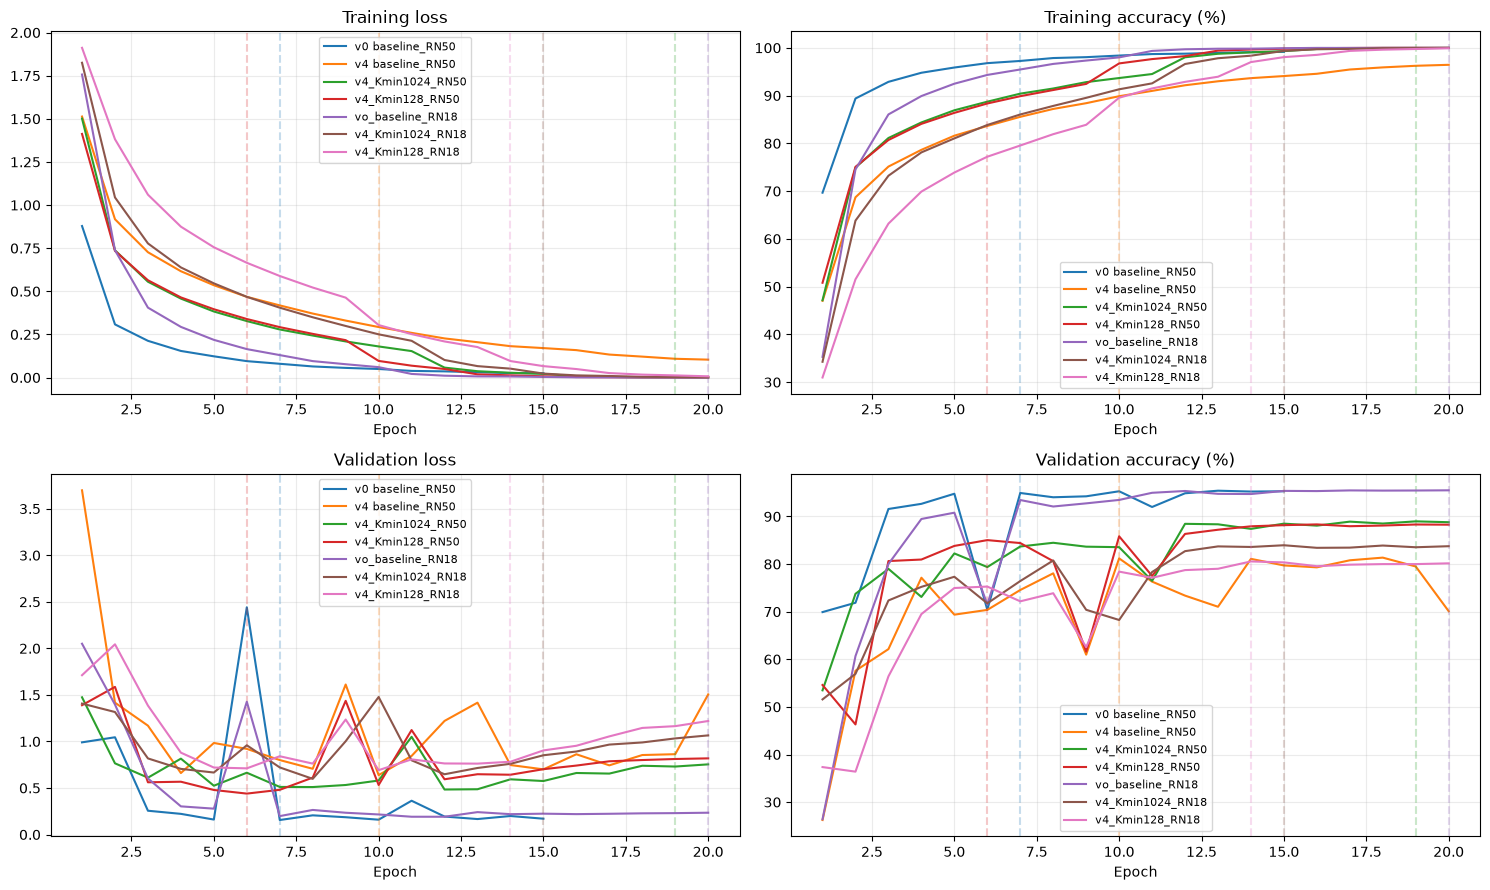

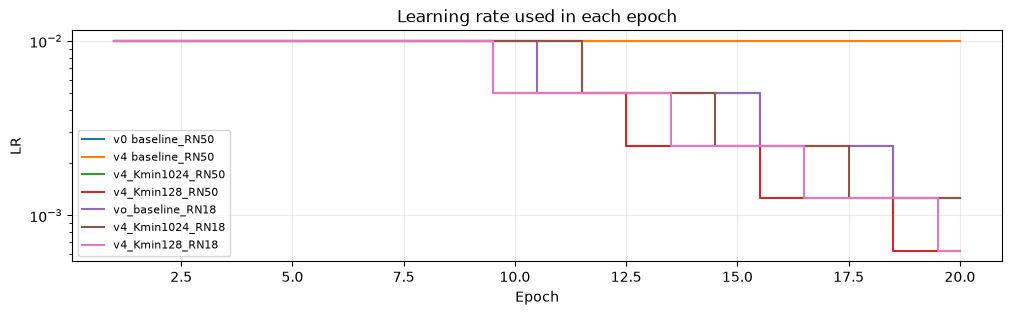

In [7]:
PLOT_RUNS = list(results)  # Replace with a smaller list of run labels if needed.
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for label in PLOT_RUNS:
    history = results[label]["history"]
    if "epoch" not in history:
        continue
    for ax, key in zip(axes.flat, ["loss", "accuracy", "val_loss", "val_accuracy"]):
        if key in history:
            line, = ax.plot(history["epoch"], history[key], label=label)
            best_epoch = results[label]["summary"]["best_epoch"]
            if best_epoch is not None:
                ax.axvline(best_epoch, color=line.get_color(), alpha=0.25, linestyle="--")
for ax, title in zip(axes.flat, ["Training loss", "Training accuracy (%)", "Validation loss", "Validation accuracy (%)"]):
    ax.set(title=title, xlabel="Epoch")
    ax.grid(alpha=0.25)
    if ax.lines:
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
for label in PLOT_RUNS:
    history = results[label]["history"]
    if {"epoch", "lr"}.issubset(history.columns):
        ax.step(history["epoch"], history["lr"], where="mid", label=label)
ax.set(title="Learning rate used in each epoch", xlabel="Epoch", ylabel="LR", yscale="log")
if ax.lines:
    ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.show()

# uncomment to plot the full history of a model
# DETAIL_RUN = PLOT_RUNS[3]
# print(f"Epoch history: {DETAIL_RUN}")
# display(results[DETAIL_RUN]["history"])

## 6. Test metrics by class
Derived from the saved confusion counts, with `rows = true class` and `columns = prediction`. Undefined ratios are shown as missing. No test evaluation is triggered. These tables describe the saved test epoch, which can differ from both the best-validation and last epochs.

In [8]:
def class_metrics(label, result):
    counts = result["test"].get("confusion_counts")
    if counts is None:
        return None, None
    counts = np.asarray(counts, dtype=float)
    if counts.ndim != 2 or counts.shape[0] != counts.shape[1] or not np.isfinite(counts).all() or (counts < 0).any():
        warnings.warn(f"Invalid confusion counts for {label}; skipped.")
        return None, None
    true_positive = np.diag(counts)
    support, predicted = counts.sum(axis=1), counts.sum(axis=0)
    divide = lambda a, b: np.divide(a, b, out=np.full_like(a, np.nan), where=b != 0)
    mapping = result["idx_to_class"]
    names = [mapping.get(i, mapping.get(str(i), str(i))) for i in range(len(counts))]
    frame = pd.DataFrame({"class": names, "precision": 100 * divide(true_positive, predicted),
                          "recall": 100 * divide(true_positive, support),
                          "f1": 100 * divide(2 * true_positive, support + predicted),
                          "support": support.astype(int), "run": label})
    return frame, counts

per_class_frames, matrices = [], {}
for label, result in results.items():
    frame, counts = class_metrics(label, result)
    if frame is not None:
        per_class_frames.append(frame)
        matrices[label] = counts

per_class = pd.concat(per_class_frames, ignore_index=True) if per_class_frames else pd.DataFrame()
CLASS_METRIC = "recall"  # "precision", "recall" or "f1"
if per_class.empty:
    print("No saved test confusion matrices available.")
else:
    class_table = per_class.pivot(index="class", columns="run", values=CLASS_METRIC)
    display(class_table.style.format("{:.2f}%", na_rep="—")
            .background_gradient(cmap="Blues", vmin=0, vmax=100, axis=None))
    print("Full per-class table (support is the true-class sample count):")
    display(per_class)


run,v0 baseline_RN50,v4 baseline_RN50,v4_Kmin1024_RN18,v4_Kmin1024_RN50,v4_Kmin128_RN18,v4_Kmin128_RN50,vo_baseline_RN18
class,,,,,,,
airplane,94.30%,89.20%,86.60%,90.20%,81.70%,90.60%,96.90%
automobile,98.60%,89.20%,90.00%,94.80%,88.00%,94.90%,97.20%
bird,91.60%,75.00%,78.90%,84.10%,81.80%,84.00%,91.90%
cat,92.60%,68.70%,68.40%,77.30%,48.10%,76.60%,87.50%
deer,95.50%,82.60%,86.80%,90.40%,72.20%,78.70%,95.10%
dog,89.60%,67.90%,77.20%,83.20%,75.30%,71.90%,90.70%
frog,96.30%,77.90%,87.80%,91.20%,80.00%,91.00%,97.50%
horse,95.70%,84.30%,88.30%,91.40%,86.20%,91.40%,96.90%
ship,97.80%,87.30%,91.20%,94.10%,86.40%,90.00%,96.50%


Full per-class table (support is the true-class sample count):


,class,precision,recall,f1,support,run
0,airplane,97.518097,94.3,95.882054,1000,v0 baseline_RN50
1,automobile,93.548387,98.6,96.007790,1000,v0 baseline_RN50
2,bird,95.416667,91.6,93.469388,1000,v0 baseline_RN50
3,cat,82.604817,92.6,87.317303,1000,v0 baseline_RN50
4,deer,95.691383,95.5,95.595596,1000,v0 baseline_RN50
...,...,...,...,...,...,...
65,dog,63.759526,75.3,69.050894,1000,v4_Kmin128_RN18
66,frog,86.673889,80.0,83.203328,1000,v4_Kmin128_RN18
67,horse,79.667283,86.2,82.804995,1000,v4_Kmin128_RN18
68,ship,86.659980,86.4,86.529795,1000,v4_Kmin128_RN18


## 7. Confusion matrices
All panels use the same 0–100% scale. Missing-support rows are masked. Check class mappings and test example identities before interpreting differences.

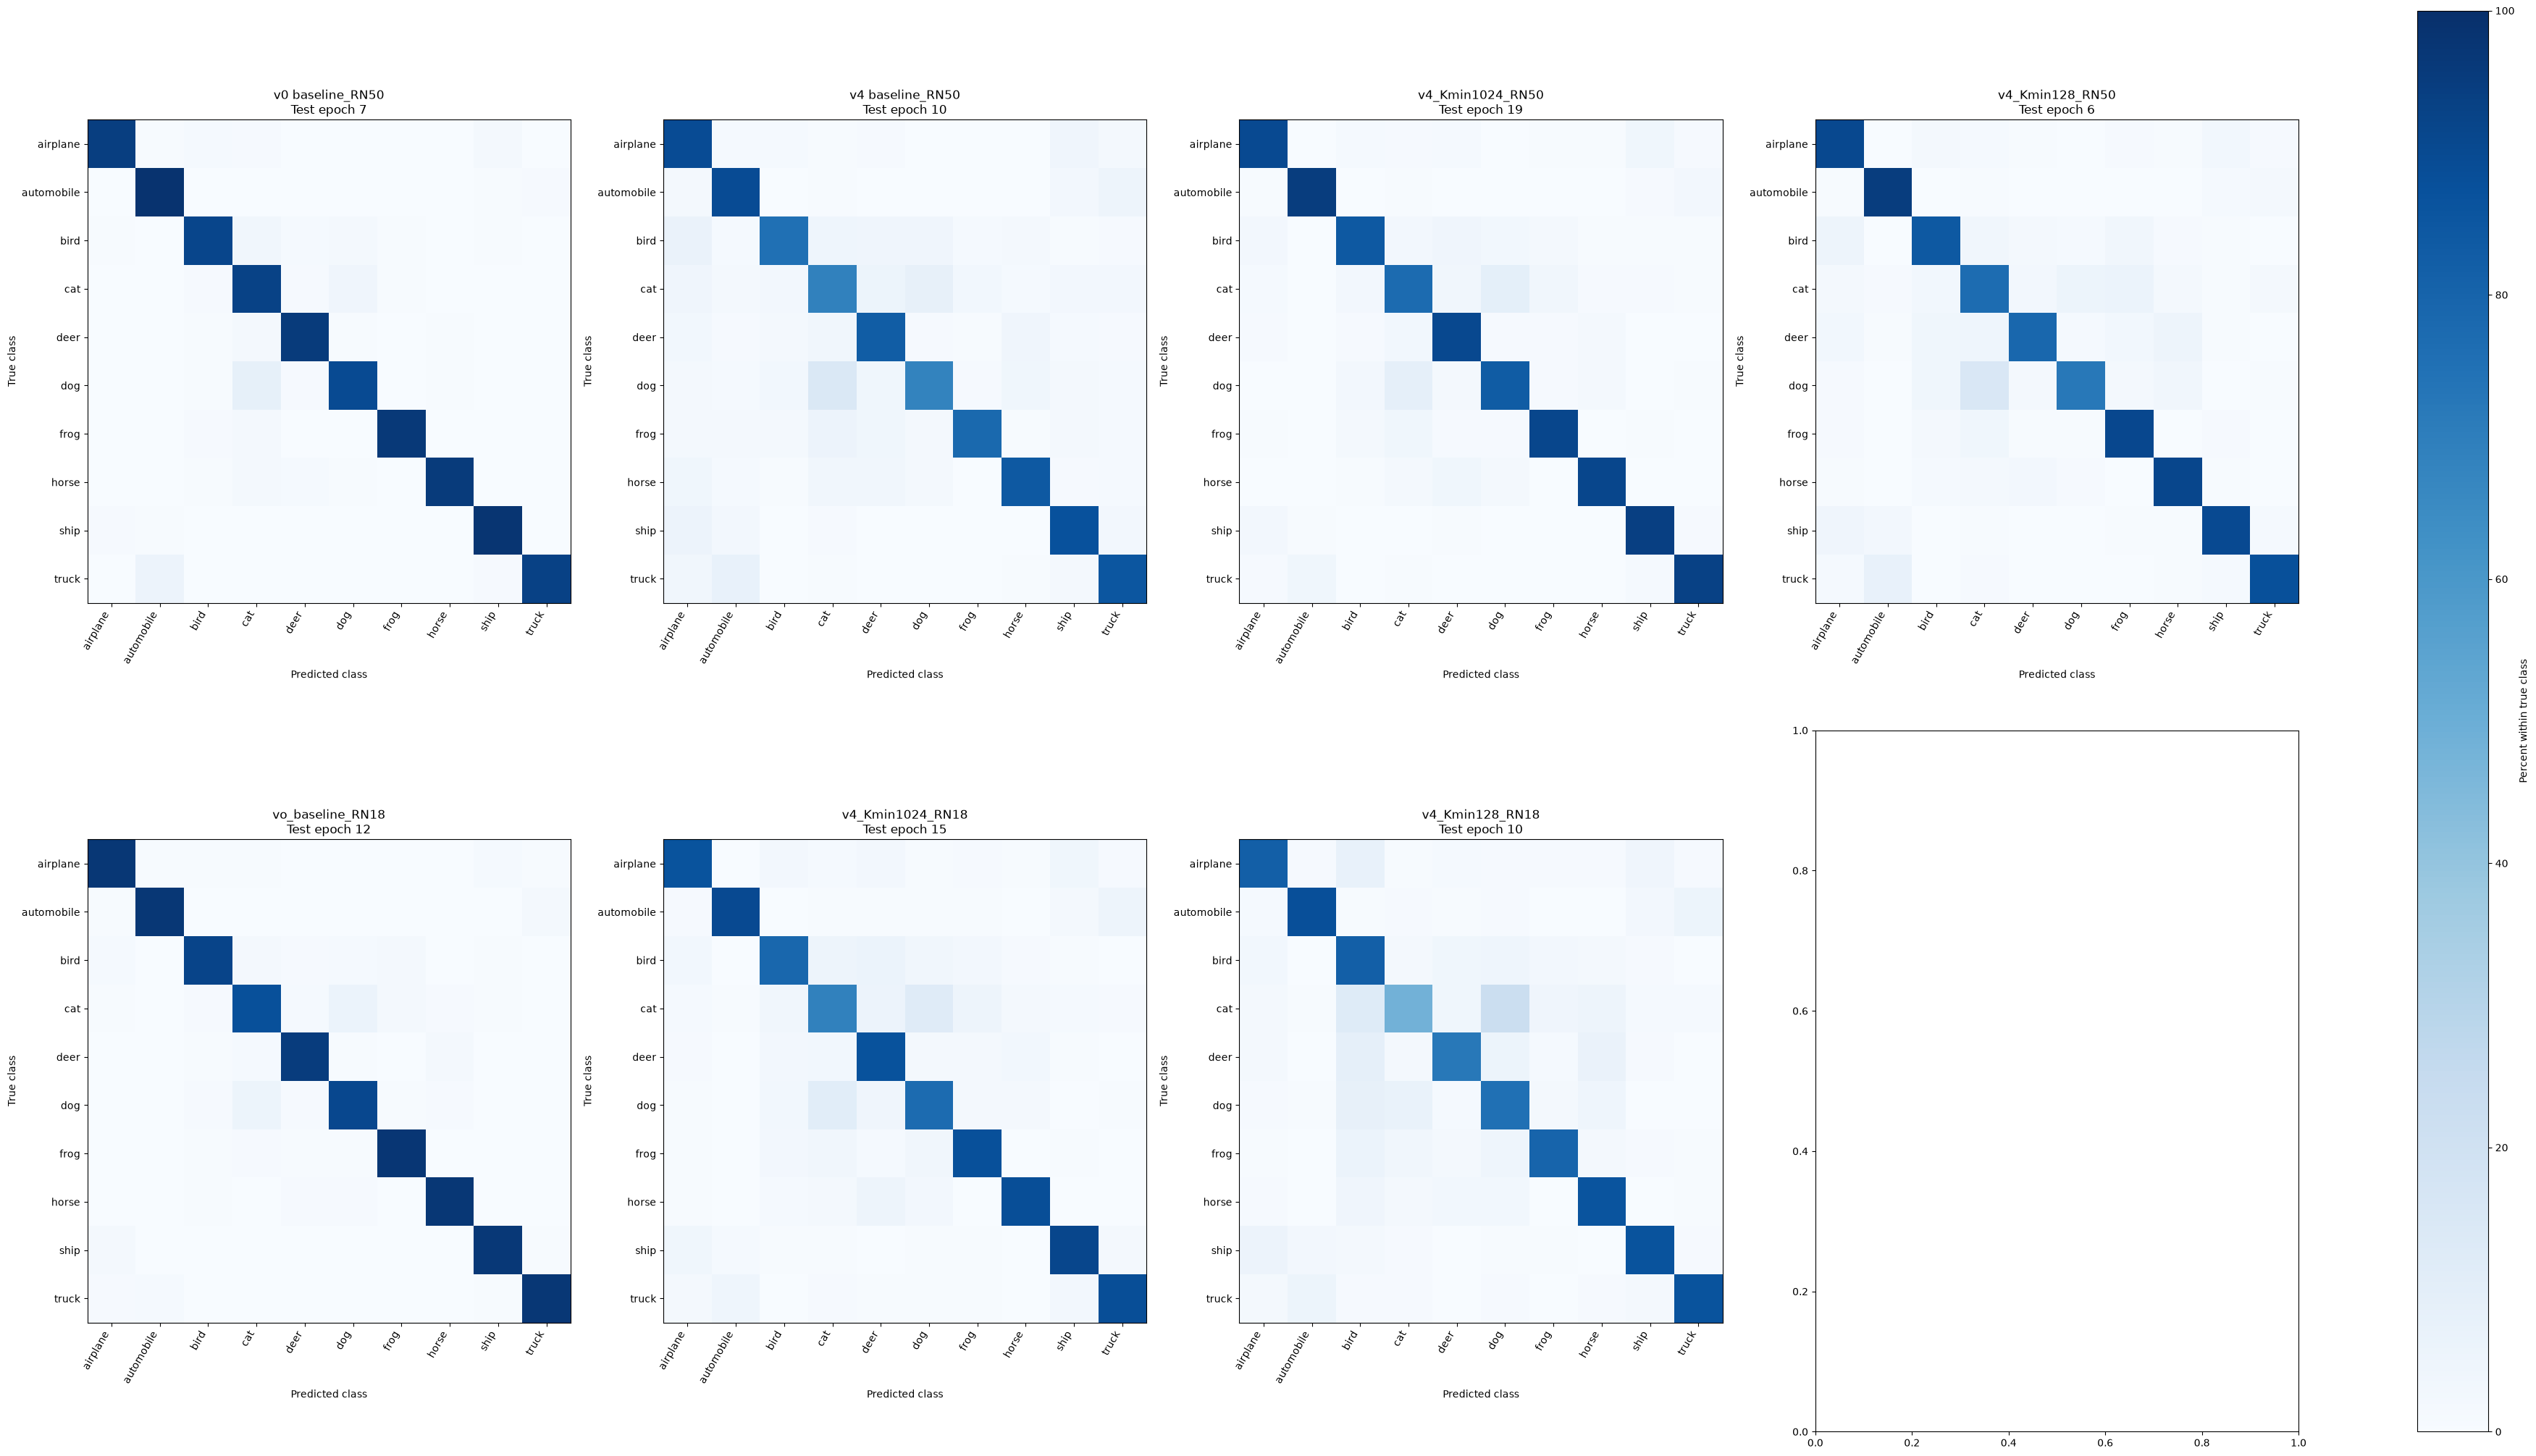

In [13]:
MATRIX_RUNS = [label for label in PLOT_RUNS if label in matrices]

if MATRIX_RUNS:
    # plot according to the amount of models selected
    if len(RUNS) // 2 == 0:
        subplots_col = len(MATRIX_RUNS)//2
    else: 
        subplots_col = len(MATRIX_RUNS)//2+1

    fig, axes = plt.subplots(2, subplots_col, figsize=(5 * len(MATRIX_RUNS), 20), squeeze=False,
                            layout="constrained")

    for ax, label in zip(axes.flat, MATRIX_RUNS):        
        counts = matrices[label]
        support = counts.sum(axis=1, keepdims=True)
        normalized = np.divide(100 * counts, support, out=np.full_like(counts, np.nan), where=support != 0)
        names = per_class.loc[per_class["run"].eq(label), "class"].tolist()
        im = ax.imshow(np.ma.masked_invalid(normalized), cmap="Blues", vmin=0, vmax=100)
        ax.set(title=f"{label}\nTest epoch {results[label]['test'].get('epoch', '?')}",
               xlabel="Predicted class", ylabel="True class",
               xticks=range(len(names)), yticks=range(len(names)), xticklabels=names, yticklabels=names)
        plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    fig.colorbar(im, ax=axes.ravel().tolist(), label="Percent within true class")
    plt.show()
else:
    print("No confusion matrices for the selected runs.")

## 8. Optional export
Set `EXPORT = True` to write CSV tables under `output/experiment_comparisons`. The default is read-only. Existing exports in that folder are replaced when this cell is enabled.

In [14]:
EXPORT = True
EXPORT_DIR = PROJECT_ROOT / "runs" / "experiment_comparisons"
if EXPORT:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(EXPORT_DIR / "summary.csv")
    deltas.to_csv(EXPORT_DIR / "differences.csv")
    for label, result in results.items():
        safe_name = hashlib.sha256(label.encode()).hexdigest()[:12]
        result["history"].to_csv(EXPORT_DIR / f"history_{safe_name}.csv", index=False)
    if not per_class.empty:
        per_class.to_csv(EXPORT_DIR /  "per_class.csv", index=False)
    print(f"Tables exported to {EXPORT_DIR}")

Tables exported to C:\Users\Edward\Desktop\AARHUS\runs\experiment_comparisons
